# Billionaires — Compare Industries: Top 10 + Other

## Goal

This analysis focuses on comparing the number of billionaires across different industries.

The dataset is first reviewed for missing values, duplicate records, repeated names, and possible formatting issues in the `Industry` column. The industry labels are then cleaned so that similar categories are counted consistently.

Next, the number of billionaires in each industry is calculated and ranked from highest to lowest. The 10 most common industries are kept as separate categories, while all remaining industries are combined into `Other`.

Finally, the results are checked to make sure all records are included correctly, and the final distribution is presented in a labeled pie chart.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

DATA_PATH = "Billionaire.csv"

billionaires = pd.read_csv(DATA_PATH)
billionaires_original = billionaires.copy()

## 1. Load and Inspect the Data

Before starting the analysis, the dataset is checked to understand its structure and make sure the data is suitable for use. This includes looking at the column types, missing values, duplicate rows, and the industry column used in the analysis.

Doing these checks first helps avoid mistakes such as creating incorrect categories or removing valid records.

In [2]:
print(f"Rows: {billionaires.shape[0]:,}")
print(f"Columns: {billionaires.shape[1]}")
display(billionaires.head())

print("\nData types:")
display(billionaires.dtypes.rename("dtype").to_frame())

print("\nMissing values:")
display(billionaires.isna().sum().rename("missing").to_frame())

print(f"\nExact duplicate rows: {billionaires.duplicated().sum()}")
print(f"Unique raw industries: {billionaires['Industry'].nunique(dropna=True)}")

Rows: 2,755
Columns: 7


,Name,NetWorth,Country,Source,Rank,Age,Industry
0,Jeff Bezos,$177 B,United States,Amazon,1,57.0,Technology
1,Elon Musk,$151 B,United States,"Tesla, SpaceX",2,49.0,Automotive
2,Bernard Arnault & family,$150 B,France,LVMH,3,72.0,Fashion & Retail
3,Bill Gates,$124 B,United States,Microsoft,4,65.0,Technology
4,Mark Zuckerberg,$97 B,United States,Facebook,5,36.0,Technology



Data types:


,dtype
Name,object
NetWorth,object
Country,object
Source,object
Rank,int64
Age,float64
Industry,object



Missing values:


,missing
Name,0
NetWorth,0
Country,0
Source,0
Rank,0
Age,79
Industry,0



Exact duplicate rows: 0
Unique raw industries: 18


### Missing Values: Why `Age` Is Not Dropped

The dataset contains some missing values in the `Age` column, but age is not needed for this analysis.

If all rows with missing age values were removed, some valid billionaire records would also be lost. This could change the number of billionaires counted in certain industries and affect the final result.

For this analysis, the better choice is to keep those rows and focus only on missing values in the `Industry` column, since that is the variable used for the comparison.

In [3]:
missing_age = billionaires["Age"].isna().sum()

print(f"Missing Age values: {missing_age}")

age_missing_by_industry = (
    billionaires.loc[billionaires["Age"].isna(), "Industry"]
    .value_counts()
    .rename("missing_age_rows")
    .to_frame()
)

display(age_missing_by_industry)

print(
    "Decision: keep these rows, because Age is not required for the "
    "industry analysis and dropping them would alter industry counts."
)

Missing Age values: 79


,missing_age_rows
Industry,
Food & Beverage,15
Manufacturing,14
Technology,10
Diversified,8
Healthcare,8
Finance & Investments,6
Fashion & Retail,5
Real Estate,4
Media & Entertainment,3


Decision: keep these rows, because Age is not required for the industry analysis and dropping them would alter industry counts.


### Data-Quality Note

There is no reason to use `dropna()` on the entire dataset just because a column such as `Age` contains missing values. Since age is not part of this analysis, removing those rows could unnecessarily change the number of billionaires counted in each industry.

The same caution applies to duplicate names. Two different people may have the same name, so records should not be removed based only on the `Name` column. A row should only be treated as a clear duplicate when the full record is the same.

### Repeated Names Are Not Automatically Duplicates

Seeing the same name more than once does not necessarily mean the records belong to the same person. Different people can share the same name.

Because of this, using something like `drop_duplicates(subset="Name")` could remove valid records. It is better to compare the repeated names with the other columns first and only remove a row when there is strong evidence that it is actually duplicated.

The code below checks repeated names together with the other available information instead of deleting them automatically.

In [4]:
repeated_names = (
    billionaires.loc[
        billionaires.duplicated(subset="Name", keep=False),
        ["Name", "NetWorth", "Country", "Source", "Rank", "Age", "Industry"]
    ]
    .sort_values(["Name", "Rank"])
)

display(repeated_names)

exact_duplicate_rows = billionaires.duplicated(keep=False)

print("Exact duplicate rows:", exact_duplicate_rows.sum())

print(
    "Decision: repeated names are kept unless the full record is duplicated "
    "or there is other evidence that the rows refer to the same person."
)

,Name,NetWorth,Country,Source,Rank,Age,Industry
693,Li Li,$4.2 B,China,healthcare,680,55.0,Healthcare
1976,Li Li,$1.6 B,China,pharmaceuticals,1931,57.0,Healthcare
1331,Robert Miller,$2.4 B,United Kingdom,retail,1299,87.0,Fashion & Retail
1625,Robert Miller,$2 B,Canada,electronics components,1580,75.0,Technology
700,Wang Yanqing & family,$4.2 B,China,electrical equipment,680,54.0,Manufacturing
1919,Wang Yanqing & family,$1.7 B,China,carbon fiber products,1833,74.0,Manufacturing


Exact duplicate rows: 0
Decision: repeated names are kept unless the full record is duplicated or there is other evidence that the rows refer to the same person.


### Repeated Ranks Do Not Mean Duplicate Records

The `Rank` column should not be treated as a unique identifier because more than one billionaire can have the same rank when there is a tie.

For this reason, repeated rank values are normal and do not mean that the related rows are duplicates or should be removed.

In [5]:
repeated_rank_rows = billionaire_repeated_ranks = (
    billionaires["Rank"].duplicated(keep=False).sum()
)

print(f"Rows involved in repeated ranks: {repeated_rank_rows}")
print("Decision: keep them. Rank is an ordering variable, not a unique identifier.")

Rows involved in repeated ranks: 2646
Decision: keep them. Rank is an ordering variable, not a unique identifier.


## 2. Clean the Industry Field

Before counting the industries, the `Industry` column is cleaned to avoid small formatting problems. Extra spaces at the beginning, end, or between words can make the same industry appear as different categories.

The text is cleaned while keeping the original wording and capitalization. Since `value_counts()` does not include missing values by default, the `Industry` column is also checked for missing or blank entries before the counting step.

In [6]:
billionaires.columns = billionaires.columns.str.strip()

billionaires["Industry"] = (
    billionaires["Industry"]
    .astype("string")
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
    .replace("", pd.NA)
)

missing_industry = billionaires["Industry"].isna().sum()

print(f"Missing/blank Industry values: {missing_industry}")

assert missing_industry == 0, ("Industry contains missing values. Handle them before continuing.")

unique_industries = billionaires["Industry"].nunique()
print(f"Unique industries: {unique_industries}")

industry_counts_with_missing = (billionaires["Industry"].value_counts(dropna=False))

assert industry_counts_with_missing.sum() == len(billionaires), (
    "Some rows are missing from the Industry counts."
)

Missing/blank Industry values: 0
Unique industries: 18


## 3. Count and Rank Industries

`value_counts()` is a simple way to count how many billionaires belong to each industry, and the result is already sorted from the highest count to the lowest.

### Important Counting Point: Do Not Count `Age`

It might seem reasonable to use:

```python
billionaires.groupby("Industry")["Age"].count()
```

but this does not give the true number of billionaires in each industry. The reason is that `.count()` only counts non-missing values in the selected column.

Since the `Age` column has some missing values, using it for counting would make some industries appear smaller than they really are.

For this analysis, we want to count billionaire records, not available age values. That is why using `billionaires["Industry"].value_counts()` is the better choice.

In [7]:
industry_counts = billionaires["Industry"].value_counts()

age_based_counts = (
    billionaires.groupby("Industry")["Age"]
    .count()
    .sort_values(ascending=False)
)

count_comparison = pd.concat(
    [
        industry_counts.rename("record_count"),
        age_based_counts.rename("non_missing_age_count")
    ],
    axis=1
)

count_comparison["difference"] = (
    count_comparison["record_count"]
    - count_comparison["non_missing_age_count"]
)

display(
    count_comparison[count_comparison["difference"] > 0]
    .sort_values("difference", ascending=False)
)

print(
    "Conclusion: use Industry.value_counts() because the analysis is counting "
    "records, not non-missing Age values."
)

,record_count,non_missing_age_count,difference
Industry,,,
Food & Beverage,219,204,15
Manufacturing,331,317,14
Technology,365,355,10
Healthcare,221,213,8
Diversified,188,180,8
Finance & Investments,371,365,6
Fashion & Retail,273,268,5
Real Estate,215,211,4
Media & Entertainment,95,92,3


Conclusion: use Industry.value_counts() because the analysis is counting records, not non-missing Age values.


In [8]:
industry_counts = billionaires["Industry"].value_counts()

display(industry_counts.rename("billionaires").to_frame())

,billionaires
Industry,
Finance & Investments,371
Technology,365
Manufacturing,331
Fashion & Retail,273
Healthcare,221
Food & Beverage,219
Real Estate,215
Diversified,188
Energy,100


## 4. Top 10 Industries + Other

For this part, the same idea used in the Messi goals notebook is applied to the industry data.

First, the industries are counted and sorted from the most common to the least common. Then the first 10 industries are kept as separate categories. All industries from the 11th position onward are added together and grouped under one category called `Other`.

In [9]:
industry_counts = billionaires["Industry"].value_counts()

top_industries = industry_counts.head(10).copy()
top_industries["Other"] = industry_counts.iloc[10:].sum()
top_industries = top_industries.sort_values(ascending=False)

display(top_industries.rename("billionaires").to_frame())

,billionaires
Industry,
Other,377
Finance & Investments,371
Technology,365
Manufacturing,331
Fashion & Retail,273
Healthcare,221
Food & Beverage,219
Real Estate,215
Diversified,188


### Validation Checks

After grouping the industries, it is important to check that no records were lost or counted more than once.

Since several smaller industries are combined into `Other`, this category may end up being larger than any single industry. If `Other` appears at the top after sorting, that is normal and does not mean there is a problem.

The 10 main industries are selected before `Other` is created. The final `sort_values()` step only changes the display order, so a large `Other` category does not affect which industries were originally included in the Top 10.

In [10]:
assert len(top_industries) == 11

assert top_industries.sum() == len(billionaires)

assert top_industries["Other"] == industry_counts.iloc[10:].sum()

result = top_industries.rename("billionaires").to_frame()
result["share_pct"] = (result["billionaires"] / len(billionaires) * 100).round(2)

display(result)

,billionaires,share_pct
Industry,,
Other,377,13.68
Finance & Investments,371,13.47
Technology,365,13.25
Manufacturing,331,12.01
Fashion & Retail,273,9.91
Healthcare,221,8.02
Food & Beverage,219,7.95
Real Estate,215,7.8
Diversified,188,6.82


## 5. Pie Chart

The final result contains 11 categories, so showing every industry name directly on the pie chart would make it look crowded.

To keep the chart clear, the percentages are displayed on the slices, while the industry names and the number of billionaires are shown in a legend. This makes the chart easier to read without losing any important information.

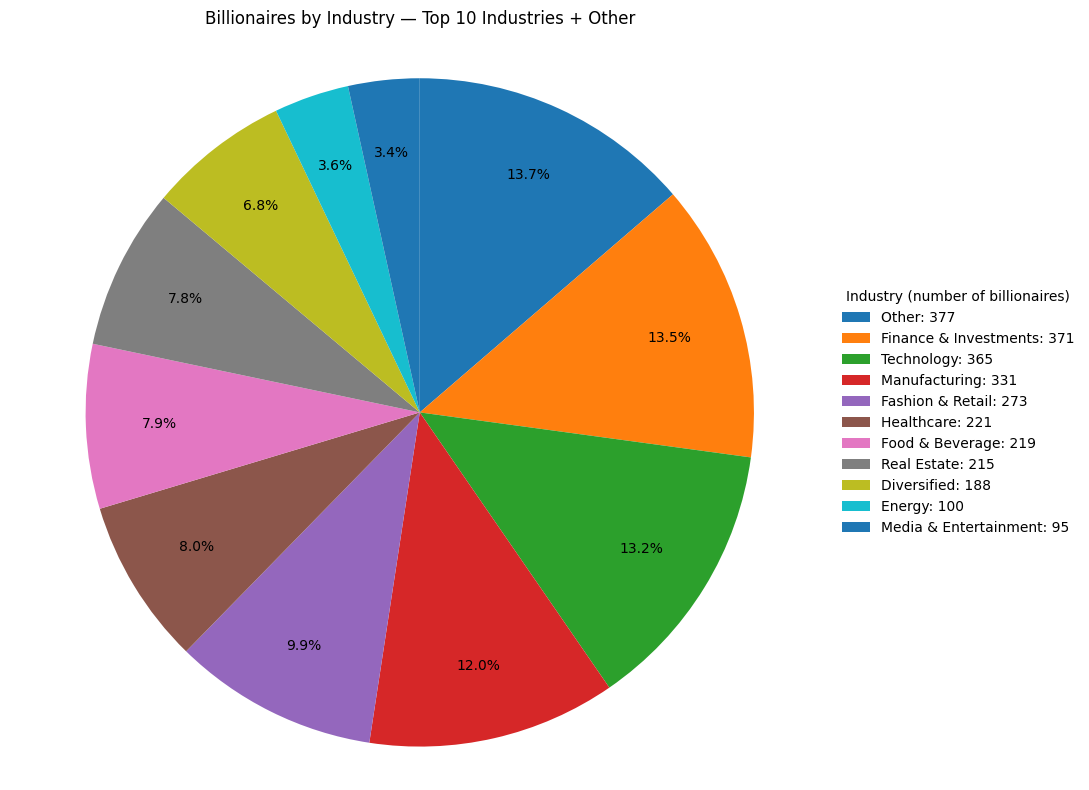

In [11]:
fig, ax = plt.subplots(figsize=(11, 8))

wedges, _, autotexts = ax.pie(
    top_industries.values,
    labels=None,
    autopct="%1.1f%%",
    startangle=90,
    counterclock=False,
    pctdistance=0.78
)

legend_labels = [
    f"{industry}: {count:,}"
    for industry, count in top_industries.items()
]

ax.legend(
    wedges,
    legend_labels,
    title="Industry (number of billionaires)",
    loc="center left",
    bbox_to_anchor=(1.0, 0.5),
    frameon=False
)

ax.set_title("Billionaires by Industry — Top 10 Industries + Other",pad=15)

ax.axis("equal")

plt.tight_layout()
plt.show()

## Interpretation

The pie chart makes the comparison easier to understand without showing all 18 industries as separate slices. The 10 most common industries are shown individually, while the remaining smaller industries are combined into `Other`.

In this dataset, `Other` represents the total of the 8 industries ranked from 11th to 18th. It is not a single industry, so its size should be understood as the combined share of those smaller categories.